# 04 - Sinh dữ liệu cho NN supervised (cấp 5)

**Ý tưởng**: NN supervised học *bắt chước một expert*. Ta cho expert chơi nhiều ván, ở **mọi thế cờ** hỏi expert "nước tốt nhất là gì?"
và lưu lại (thế cờ, nước của expert, kết quả cuối ván). Mạng sau đó học dự đoán lại nước của expert (policy) và kết quả ván (value).

Quy trình trong notebook:
1. Đọc cấu hình từ `configs/train_supervised.yaml` (có thể chỉnh tay ở ô cấu hình).
2. Định nghĩa hàm sinh 1 ván, dedupe, chia train/val/test **theo ván**.
3. Xem thử 1 ván, rồi sinh toàn bộ.
4. Thống kê, kiểm tra (không rò rỉ giữa các split, nhãn luôn hợp lệ).
5. Lưu data (đầu vào của notebook 05).

In [14]:
import json, os, random, sys, tempfile, time
from datetime import datetime
from pathlib import Path

# Chạy từ thư mục notebooks/ hay thư mục gốc đều được: luôn chuyển về thư mục gốc repo để đường dẫn trong config đúng.
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from tqdm.auto import tqdm

from agents.registry import build_agent_by_name, check_spec, load_agent_specs
from models.nets import legal_mask_from_actions
from othello.encoding import BLACK, action_to_index, index_to_action
from othello.game import OthelloGame

# QUICK_TEST = True: chạy thử cả notebook trong vài giây với dữ liệu/số vòng rất nhỏ, ghi ra thư mục tạm
# (để kiểm tra mọi thứ chạy được trước khi chạy thật). Chạy chính thức: để False.
QUICK_TEST = False

## 1. Cấu hình
Mọi tham số lấy từ YAML để tái lập được; muốn thử giá trị khác thì sửa ngay ở ô này (không cần sửa file YAML) nhưng
nhớ ghi lại giá trị đã dùng. `meta.json` sẽ lưu lại các giá trị thực tế.

In [15]:
with open(REPO / "configs" / "train_supervised.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
dcfg = cfg["data"]

SEED = int(cfg["seed"])                       # seed gốc; ván thứ i dùng seed = SEED * 1_000_000 + i (tái lập được)
EXPERT = dcfg["expert_agent"]                 # tên mục trong configs/agents.yaml (vd temp_positional, alphabeta)
NUM_GAMES = int(dcfg["num_games"])            # số ván sinh ra TRƯỚC khi loại trùng
OPENING_PLIES = int(dcfg["opening_plies"])    # số nước đầu đi ngẫu nhiên (để các ván khác nhau)
RANDOM_MOVE_PROB = float(dcfg["random_move_prob"])   # sau khai cuộc: xác suất đi ngẫu nhiên thay vì theo expert
SPLIT = dcfg["split"]                         # tỷ lệ train/val/test, chia THEO VÁN
OUT_DIR = REPO / dcfg["output_dir"]
NUM_WORKERS = dcfg.get("num_workers", "auto")   # số tiến trình sinh ván; "auto" = số lõi CPU - 1 (đặt 1 để chạy tuần tự)
NUM_WORKERS = None if NUM_WORKERS in (None, "auto") else int(NUM_WORKERS)

if QUICK_TEST:
    NUM_GAMES, OUT_DIR = 40, Path(tempfile.mkdtemp()) / "data"

# Không ghi đè dữ liệu cũ: muốn sinh lại thì đổi OUT_DIR hoặc xóa thư mục cũ.
if OUT_DIR.exists() and any(OUT_DIR.iterdir()):
    raise FileExistsError(f"{OUT_DIR} đã có dữ liệu. Đổi OUT_DIR (hoặc data.output_dir trong YAML) hoặc xóa thư mục cũ.")
if not dcfg.get("split_by_game", True):
    raise ValueError("Đề yêu cầu chia THEO VÁN: data.split_by_game phải là true")

# Expert phải dùng được (agent chưa code hoặc thiếu checkpoint sẽ bị báo ngay ở đây).
ok, reason = check_spec(load_agent_specs()[EXPERT])
assert ok, f"Expert '{EXPERT}' chưa dùng được: {reason}. Sửa data.expert_agent trong configs/train_supervised.yaml."
print(f"Expert={EXPERT} | {NUM_GAMES} ván | opening_plies={OPENING_PLIES} | random_move_prob={RANDOM_MOVE_PROB} | -> {OUT_DIR}")

Expert=alphabeta | 5000 ván | opening_plies=8 | random_move_prob=0.05 | -> c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\data\supervised_alphabeta_v1


## 2. Hàm sinh dữ liệu

`generate_one_game` chơi **một** ván:
- Ở mỗi thế cờ: hỏi expert nước tốt nhất `best` → ghi mẫu `(bàn cờ, người đi, nhãn = best, mặt nạ nước hợp lệ)`.
- Nước **thực sự đi** trên bàn có thể khác `best`: `opening_plies` nước đầu chọn ngẫu nhiên, sau đó xác suất `random_move_prob` đi ngẫu nhiên.
  Lý do: expert tất định thì mọi ván giống hệt nhau, dedupe sẽ xóa gần hết. **Nhãn vẫn luôn là nước của expert**, không phải nước ngẫu nhiên.
- Cuối ván: nhãn value của mọi mẫu = kết quả ván theo góc nhìn người đi tại mẫu đó (+1 thắng, 0 hòa, -1 thua).

`split_game_ids` chia **chỉ số ván** (không chia từng nước) để không rò rỉ: hai thế cờ liền nhau của cùng một ván mà rơi vào train và test thì điểm test sẽ cao giả tạo.

In [16]:
SEED_STRIDE = 1_000_000


# generate_one_game / generate_games nằm trong train/data_gen.py (để chạy song song được, kể cả trên Windows).
from notebooks.data_gen import generate_games, generate_one_game


def split_game_ids(n_games, ratios, seed):
    """Chia chỉ số ván 0..n-1 cho train/val/test theo tỷ lệ (xáo theo seed). Mỗi ván thuộc đúng 1 split."""
    if abs(sum(ratios.values()) - 1.0) > 1e-9:
        raise ValueError(f"split phải có tổng = 1, nhận {ratios}")
    order = np.random.RandomState(seed).permutation(n_games)
    n_val = int(round(n_games * ratios.get("val", 0.0)))
    n_test = int(round(n_games * ratios.get("test", 0.0)))
    n_train = n_games - n_val - n_test
    if min(n_train, n_val, n_test) <= 0:
        raise ValueError(f"Quá ít ván ({n_games}) để chia {ratios}: mỗi split cần >= 1 ván")
    return {"train": sorted(order[:n_train].tolist()),
            "val": sorted(order[n_train:n_train + n_val].tolist()),
            "test": sorted(order[n_train + n_val:].tolist())}


def build_dataset(games, ratios, seed):
    """Loại ván trùng -> chia theo ván -> gom mẫu theo split. Trả về (splits, ván giữ lại, thống kê)."""
    seen, kept = set(), []
    for g in games:
        key = tuple(map(tuple, g["moves"]))              # hai ván trùng nếu cùng chuỗi nước đã đi
        if key not in seen:
            seen.add(key)
            kept.append(g)
    ids = split_game_ids(len(kept), ratios, seed)

    splits = {}
    for name, game_ids in ids.items():
        parts = {k: [] for k in ("board", "player", "action", "value", "legal", "game_id", "ply")}
        for gid in game_ids:
            g = kept[gid]
            for k in ("board", "player", "action", "value", "legal", "ply"):
                parts[k].append(g[k])
            parts["game_id"].append(np.full(len(g["action"]), gid, dtype=np.int32))
            g["split"] = name
        splits[name] = {k: np.concatenate(v) for k, v in parts.items()}
    stats = {"games_before_dedupe": len(games), "games_after_dedupe": len(kept),
             "duplicates_removed": len(games) - len(kept),
             "games_per_split": {k: len(v) for k, v in ids.items()},
             "samples_per_split": {k: int(len(v["action"])) for k, v in splits.items()}}
    return splits, kept, stats

## 3. Xem thử một ván
Cột `expert` là nhãn (nước expert muốn đi). Cột `played` là nước thực sự đi. Ở các nước đầu (khai cuộc ngẫu nhiên) hai cột thường khác nhau,
nhưng nhãn vẫn là `expert`.

In [17]:
def sq(a):  # (row, col) -> 'd3'
    return "abcdefgh"[a[1]] + str(a[0] + 1)

demo = generate_one_game(SEED * SEED_STRIDE, EXPERT, OPENING_PLIES, RANDOM_MOVE_PROB)
rows = []
for t in range(min(16, len(demo["moves"]))):
    expert_move, played = index_to_action(demo["action"][t]), tuple(demo["moves"][t])
    rows.append({"ply": t, "người đi": "Đen" if demo["player"][t] == BLACK else "Trắng",
                 "expert (nhãn)": sq(expert_move), "played (đi thật)": sq(played),
                 "khác nhau?": expert_move != played, "số nước hợp lệ": int(demo["legal"][t].sum()),
                 "value (nhãn)": float(demo["value"][t])})
display(pd.DataFrame(rows))
print(f"Ván demo dài {len(demo['moves'])} nước, kết quả (góc nhìn Đen): {demo['result_black']}")

,ply,người đi,expert (nhãn),played (đi thật),khác nhau?,số nước hợp lệ,value (nhãn)
0,0,Đen,d3,c4,True,4,1.0
1,1,Trắng,e3,c3,True,3,-1.0
2,2,Đen,e6,f5,True,4,1.0
3,3,Trắng,b4,f6,True,5,-1.0
4,4,Đen,d3,f7,True,4,1.0
5,5,Trắng,c5,c5,False,7,-1.0
6,6,Đen,b5,b2,True,5,1.0
7,7,Trắng,f4,e3,True,6,-1.0
8,8,Đen,b4,b4,False,4,1.0
9,9,Trắng,d3,e6,True,7,-1.0


Ván demo dài 60 nước, kết quả (góc nhìn Đen): 1


## 4. Sinh toàn bộ ván
Chạy tuần tự một tiến trình. Với expert Alpha-Beta sẽ lâu hơn nhiều, nên thử `NUM_GAMES` nhỏ trước để đo thời gian.

In [18]:
t0 = time.perf_counter()
games = generate_games(NUM_GAMES, SEED * SEED_STRIDE, EXPERT, OPENING_PLIES, RANDOM_MOVE_PROB, workers=NUM_WORKERS,
                       progress=lambda it, total: tqdm(it, total=total, desc="sinh ván"))
gen_seconds = time.perf_counter() - t0
print(f"Sinh xong {len(games)} ván trong {gen_seconds:.1f}s")


sinh ván:   0%|          | 0/5000 [00:00<?, ?it/s]

Sinh xong 5000 ván trong 1083.0s


## 5. Loại trùng, chia theo ván, thống kê

,số ván,số mẫu (vị trí)
train,4000,239485
val,500,29961
test,500,29942


Ván trước dedupe: 5000 | sau dedupe: 5000 (loại 0 ván trùng)


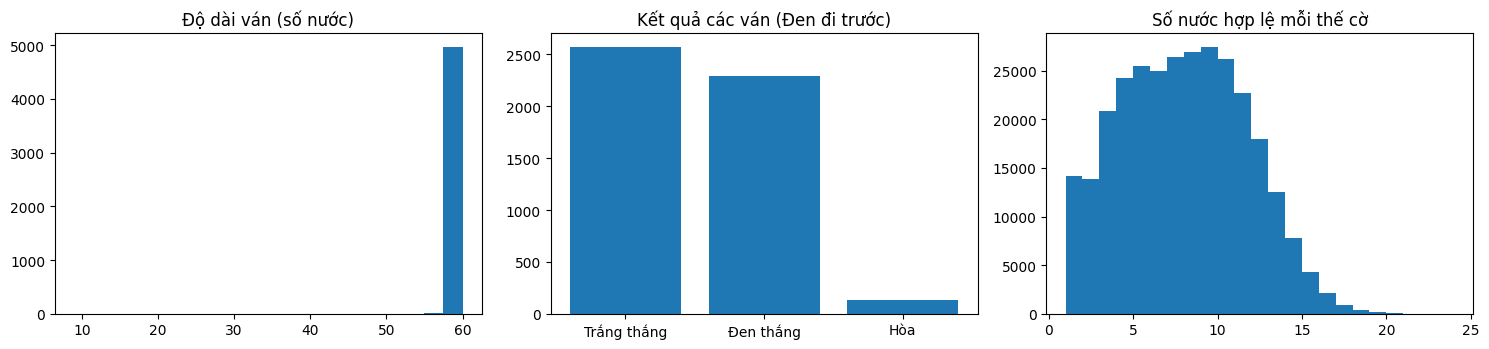

In [19]:
splits, kept, stats = build_dataset(games, SPLIT, SEED)
display(pd.DataFrame({"số ván": stats["games_per_split"], "số mẫu (vị trí)": stats["samples_per_split"]}))
print(f"Ván trước dedupe: {stats['games_before_dedupe']} | sau dedupe: {stats['games_after_dedupe']} "
      f"(loại {stats['duplicates_removed']} ván trùng)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist([len(g["moves"]) for g in kept], bins=20); ax[0].set_title("Độ dài ván (số nước)")
res = pd.Series([g["result_black"] for g in kept]).map({1: "Đen thắng", 0: "Hòa", -1: "Trắng thắng"}).value_counts()
ax[1].bar(res.index, res.values); ax[1].set_title("Kết quả các ván (Đen đi trước)")
n_legal = np.concatenate([s["legal"].sum(1) for s in splits.values()])
ax[2].hist(n_legal, bins=range(1, int(n_legal.max()) + 2)); ax[2].set_title("Số nước hợp lệ mỗi thế cờ")
plt.tight_layout(); plt.show()

### Kiểm tra tính đúng đắn (nếu một dòng `assert` lỗi thì KHÔNG dùng dữ liệu này)

In [20]:
ids = {s: set(np.unique(d["game_id"]).tolist()) for s, d in splits.items()}
assert not (ids["train"] & ids["val"] or ids["train"] & ids["test"] or ids["val"] & ids["test"]), "rò rỉ: ván nằm ở nhiều split"
for name, d in splits.items():
    rows_ = np.arange(len(d["action"]))
    assert d["legal"][rows_, d["action"]].all(), f"{name}: có nhãn là nước không hợp lệ"
    assert set(np.unique(d["value"])) <= {-1.0, 0.0, 1.0}
print("OK: không rò rỉ giữa split, mọi nhãn policy đều là nước hợp lệ, nhãn value ∈ {-1, 0, 1}")
print("Tỷ lệ value=+1 ở tập train:", float((splits["train"]["value"] == 1).mean()).__round__(3),
      "(gần 0.5 là cân bằng giữa bên thắng/thua)")

OK: không rò rỉ giữa split, mọi nhãn policy đều là nước hợp lệ, nhãn value ∈ {-1, 0, 1}
Tỷ lệ value=+1 ở tập train: 0.495 (gần 0.5 là cân bằng giữa bên thắng/thua)


## 6. Lưu dữ liệu
Ghi `train/val/test.npz`, `games.jsonl` (mỗi ván 1 dòng, có cột `split`) và `meta.json` (nguồn nhãn, seed, số ván trước/sau dedupe).
Notebook 05 đọc đúng thư mục này.

In [21]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
for name, arrays in splits.items():
    np.savez_compressed(OUT_DIR / f"{name}.npz", **arrays)
with open(OUT_DIR / "games.jsonl", "w", encoding="utf-8") as f:
    for gid, g in enumerate(kept):
        f.write(json.dumps({"id": gid, "split": g["split"], "result_black": g["result_black"], "moves": g["moves"]},
                           ensure_ascii=False) + "\n")
meta = {
    "created_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "label_source": {
        "expert_agent": EXPERT,
        "is_temporary_expert": EXPERT == "temp_positional",
        "note": "policy = nước của expert; value = kết quả cuối ván theo góc nhìn người đang đi. "
                "Mô hình học từ dữ liệu này có nguy cơ chỉ học lại expert (đề mục 3.4).",
    },
    "seed": SEED, "opening_plies": OPENING_PLIES, "random_move_prob": RANDOM_MOVE_PROB,
    "split_ratios": SPLIT, "split_by_game": True, "generation_seconds": round(gen_seconds, 1), "workers": NUM_WORKERS or "auto", **stats,
}
with open(OUT_DIR / "meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT_DIR.iterdir()), "->", OUT_DIR)

Đã lưu: ['games.jsonl', 'meta.json', 'test.npz', 'train.npz', 'val.npz'] -> c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\data\supervised_alphabeta_v1
